In [2]:
import os

import keras
import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt


from keras import layers
from keras.utils     import to_categorical
from keras.callbacks import EarlyStopping, ReduceLROnPlateau

"""
CNNs are specifically designed for image data. They outperform classical ML on MNIST by learning spatial features (edges, curves, strokes) directly from raw pixels.

Architecture:

Input (28×28×1)
  → Conv2D(32) + BatchNorm + ReLU
  → Conv2D(64) + BatchNorm + ReLU + MaxPool + Dropout(0.25)
  → Conv2D(128) + BatchNorm + ReLU + MaxPool + Dropout(0.25)
  → Flatten
  → Dense(256) + BatchNorm + ReLU + Dropout(0.5)
  → Dense(10, Softmax)"""


# load the MNIST dataset
#(X_train, y_train), (X_test, y_test) = tf.keras.datasets.mnist.load_data()
X_train_cnn = np.load('X_train_cnn.npy')
X_val_cnn   = np.load('X_val_cnn.npy')
y_train     = np.load('y_train.npy')
y_val       = np.load('y_val.npy')




In [3]:
def reshape_and_encode(X_train_cnn, X_val_cnn, y_train, y_val):
    """
    Reshape and one-hot encode the data for CNN.
    """
    # reshape to (num_samples, 28, 28, 1)
    X_train_cnn_4d = X_train_cnn.reshape(-1, 28, 28, 1)
    X_val_cnn_4d   = X_val_cnn.reshape(-1, 28, 28, 1)

    # one-hot encode the labels
    y_train_ohe = to_categorical(y_train, num_classes=10)
    y_val_ohe   = to_categorical(y_val, num_classes=10)

    return X_train_cnn_4d, X_val_cnn_4d, y_train_ohe, y_val_ohe

X_train_cnn_4d, X_val_cnn_4d, y_train_ohe, y_val_ohe = reshape_and_encode(X_train_cnn, X_val_cnn, y_train, y_val)




In [4]:
def build_cnn_model(input_shape=(28, 28, 1), num_classes=10):
    """
    Build a CNN model for MNIST classification.
    """
    model = keras.Sequential([
        # Input layer
        layers.Input(shape=input_shape),

        # input layer processing
        layers.Conv2D(32, kernel_size=(3, 3), padding='same'),
        layers.BatchNormalization(),
        layers.Activation('relu'),

        # Hidden layers 1
        layers.Conv2D(64, kernel_size=(3, 3), padding='same'),
        layers.BatchNormalization(),
        layers.Activation('relu'),
        layers.MaxPooling2D(pool_size=(2, 2)),
        layers.Dropout(0.25),

        # Hidden layers 2
        layers.Conv2D(128, kernel_size=(3, 3), padding='same'),
        layers.BatchNormalization(),
        layers.Activation('relu'),
        layers.MaxPooling2D(pool_size=(2, 2)),
        layers.Dropout(0.25),

        # Classifier head
        layers.Flatten(),
        layers.Dense(256),
        layers.BatchNormalization(),
        layers.Activation('relu'),
        layers.Dropout(0.5),
        layers.Dense(num_classes, activation='softmax')
    ])

    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=0.001),
        loss='categorical_crossentropy',
        metrics=['accuracy'])

    return model



In [5]:
def train_cnn_model(X_train_cnn_4d, y_train_ohe, X_val_cnn_4d, y_val_ohe):
    """
    Train the CNN model.
    """
    cnn_model = build_cnn_model(input_shape=(28, 28, 1), num_classes=10)
    cnn_model.summary()

    # ── Callbacks ─────────────────────────────────────────────────────────
    early_stop = EarlyStopping(
        monitor='val_accuracy', patience=5,
        restore_best_weights=True, verbose=1
    )
    reduce_lr = ReduceLROnPlateau(
        monitor='val_loss', factor=0.5,
        patience=3, min_lr=1e-6, verbose=1
    )

    # ── Train ─────────────────────────────────────────────────────────────
    history = cnn_model.fit(
        X_train_cnn_4d, y_train_ohe,
        validation_data=(X_val_cnn_4d, y_val_ohe),
        epochs=30,
        batch_size=128,
        callbacks=[early_stop, reduce_lr],
        verbose=1
    )

    return cnn_model, history




In [6]:
def plot_training_history(history):
    """
    Plot the training and validation accuracy and loss.
    """
    # Accuracy plot
    plt.figure(figsize=(12, 5))
    plt.subplot(1, 2, 1)
    plt.plot(history.history['accuracy'], label='Train Accuracy', color='#3498db')
    plt.plot(history.history['val_accuracy'], label='Validation Accuracy', color='#e74c3c')
    plt.title('Model Accuracy', fontsize=14, fontweight='bold')
    plt.xlabel('Epochs', fontsize=12)
    plt.ylabel('Accuracy', fontsize=12)
    plt.legend()
    plt.grid(alpha=0.3)

    # Loss plot
    plt.subplot(1, 2, 2)
    plt.plot(history.history['loss'], label='Train Loss', color='#3498db')
    plt.plot(history.history['val_loss'], label='Validation Loss', color='#e74c3c')
    plt.title('Model Loss', fontsize=14, fontweight='bold')
    plt.xlabel('Epochs', fontsize=12)
    plt.ylabel('Loss', fontsize=12)
    plt.legend()
    plt.grid(alpha=0.3)

    plt.tight_layout()

    os.makedirs('artifacts/DeepML', exist_ok=True)
    cnn_save_path = 'artifacts/DeepML/cnn_training_history.png'
    os.makedirs(os.path.dirname(cnn_save_path), exist_ok=True)


    plt.savefig(cnn_save_path, dpi=150, bbox_inches='tight')
    print('✅ Saved: artifacts/DeepML/cnn_training_history.png')




In [9]:
def save_cnn_model(cnn_model):
    """
    Save the trained CNN model.
    """
    os.makedirs('artifacts/DeepML', exist_ok=True)
    model_save_path = 'artifacts/DeepML/cnn_model.keras'
    keras.saving.save_model(cnn_model, model_save_path)
    #cnn_model.save(model_save_path)
    print(f'✅ Saved: {model_save_path}')   # to later load model, use keras.models.load_model('artifacts/DeepML/cnn_model.h5')

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_3 (Conv2D)               │ (None, 28, 28, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 28, 28, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_4 (Activation)       │ (None, 28, 28, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 28, 28, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_5           │ (None, 28, 28, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_5 (Activation)       │ (None, 28, 28, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 14, 14, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_6           │ (None, 14, 14, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_6 (Activation)       │ (None, 14, 14, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 7, 7, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 7, 7, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 6272)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 256)            │     1,605,888 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_7           │ (None, 256)            │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_7 (Activation)       │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 10)             │         2,570 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,703,050 (6.50 MB)

 Trainable params: 1,702,090 (6.49 MB)

 Non-trainable params: 960 (3.75 KB)

Epoch 1/30
263/263 ━━━━━━━━━━━━━━━━━━━━ 17s 37ms/step - accuracy: 0.9436 - loss: 0.1888 - val_accuracy: 0.1115 - val_loss: 5.7130 - learning_rate: 0.0010
Epoch 2/30
263/263 ━━━━━━━━━━━━━━━━━━━━ 4s 15ms/step - accuracy: 0.9793 - loss: 0.0690 - val_accuracy: 0.9535 - val_loss: 0.1499 - learning_rate: 0.0010
Epoch 3/30
263/263 ━━━━━━━━━━━━━━━━━━━━ 4s 16ms/step - accuracy: 0.9843 - loss: 0.0509 - val_accuracy: 0.9856 - val_loss: 0.0436 - learning_rate: 0.0010
Epoch 4/30
263/263 ━━━━━━━━━━━━━━━━━━━━ 5s 15ms/step - accuracy: 0.9868 - loss: 0.0420 - val_accuracy: 0.9880 - val_loss: 0.0396 - learning_rate: 0.0010
Epoch 5/30
263/263 ━━━━━━━━━━━━━━━━━━━━ 4s 15ms/step - accuracy: 0.9888 - loss: 0.0369 - val_accuracy: 0.9818 - val_loss: 0.0549 - learning_rate: 0.0010
Epoch 6/30
263/263 ━━━━━━━━━━━━━━━━━━━━ 4s 15ms/step - accuracy: 0.9898 - loss: 0.0331 - val_accuracy: 0.9900 - val_loss: 0.0300 - learning_rate: 0.0010
Epoch 7/30
263/263 ━━━━━━━━━━━━━━━━━━━━ 4s 15ms/step - accuracy: 0.9907 - loss: 0

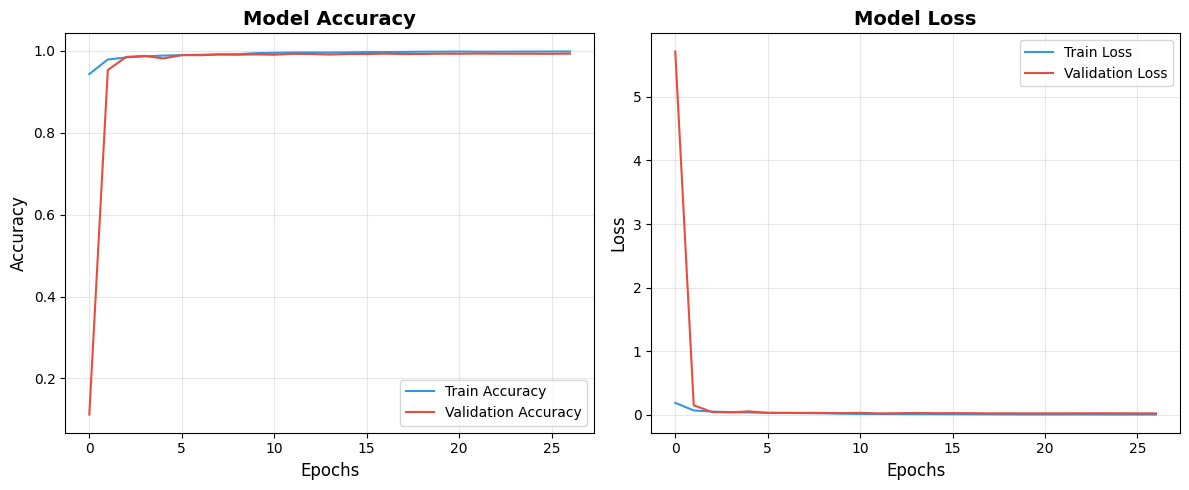

In [10]:
cnn_model, history = train_cnn_model(X_train_cnn_4d, y_train_ohe, X_val_cnn_4d, y_val_ohe)
plot_training_history(history)
save_cnn_model(cnn_model)

In [ ]:
# Evaluation

cnn_loss, cnn_accuracy = cnn_model.evaluate(X_val_cnn_4d, y_val_ohe,verbose=0)
cnn_preds_prob = cnn_model.predict(X_val_cnn_4d, verbose=0)
cnn_preds = np.argmax(cnn_preds_prob, axis=1)

print(f'CNN Loss: {cnn_loss:.4f}')
print(f'CNN Accuracy: {cnn_accuracy:.4f}')
#